### IPD440 - APRENDIZAJE DE MAQUINAS
# Clase 7: Building blocks of neural nets
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Data representations for neural networks

# Tensores

Un tensor es un contenedor de datos numéricos con una cantidad arbitraria de dimensiones (rango).

<div align="center">
    <img src="img/tensor.png" alt="" width="40%" align="center" />
</div>

In [1]:
import numpy as np

## Escalares (tensores 0D)

Un tensor que contiene solo un número se llama escalar (o tensor escalar, o tensor de dimensión 0, o tensor 0D).

In [2]:
x = np.array(12)
x

array(12)

In [3]:
x.ndim

0

## Vectores (tensores 1D)

Un arreglo de números es llamado vector o tensor 1D porque contiene una dimensión (un eje).

In [4]:
x = np.array([12, 3, 6, 14])
x

array([12,  3,  6, 14])

In [5]:
x.ndim

1

## Matrices (tensores 2D)

Un arreglo de vectores es una matriz, o tensor 2D.

In [6]:
x = np.array([[5, 78, 2, 34, 0], [6, 79, 3, 35, 1], [7, 80, 4, 36, 2]])

In [7]:
x

array([[ 5, 78,  2, 34,  0],
       [ 6, 79,  3, 35,  1],
       [ 7, 80,  4, 36,  2]])

In [8]:
x.ndim

2

## Tensores 3D y dimensiones superiores

Un arreglo de matrices es un tensor 3D, que puede interpretarse visualmente como un cubo de números.

In [9]:
x = np.array([[[5, 78, 2, 34, 0], [6, 79, 3, 35, 1], [7, 80, 4, 36, 2]], [[5, 78, 2, 34, 0], 
[6, 79, 3, 35, 1], [7, 80, 4, 36, 2]], [[5, 78, 2, 34, 0], [6, 79, 3, 35, 1], [7, 80, 4, 36, 2]]])

In [10]:
x

array([[[ 5, 78,  2, 34,  0],
        [ 6, 79,  3, 35,  1],
        [ 7, 80,  4, 36,  2]],

       [[ 5, 78,  2, 34,  0],
        [ 6, 79,  3, 35,  1],
        [ 7, 80,  4, 36,  2]],

       [[ 5, 78,  2, 34,  0],
        [ 6, 79,  3, 35,  1],
        [ 7, 80,  4, 36,  2]]])

In [11]:
x.ndim

3

# Características de un tensor

- Rango: Número de ejes o dimensiones del tensor.

In [12]:
x.ndim

3

- Forma (`shape`): esta es una tupla de enteros que describe cuántas dimensiones tiene el tensor a lo largo de cada eje.

In [13]:
x.shape

(3, 3, 5)

- Tipo de datos: este es el tipo de datos contenidos en el tensor. Por ejemplo, el tipo de un tensor podría ser `float32`, `uint8`, `float64`, etc. En general, no se aceptan `strings` porque los tensores reservan un espacio fijo en memoria.

In [14]:
x.dtype

dtype('int32')

# Image data

Las imágenes suelen tener tres dimensiones: alto, ancho y canal de color `(height, width, channels)`. Aunque las imágenes en escala de grises (como los dígitos MNIST) tienen un solo canal de color y, por lo tanto, podrían almacenarse en tensores 2D.

In [15]:
import matplotlib.pyplot as plt

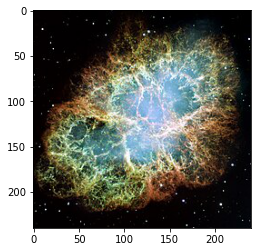

In [16]:
img = plt.imread("img/Crab_Nebula.jpg")
plt.imshow(img)
plt.show()

In [17]:
img.shape

(240, 240, 3)

In [18]:
img.ndim

3

### MNIST

In [19]:
from keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

In [20]:
train_images.ndim

3

In [21]:
train_images.shape

(60000, 28, 28)

In [22]:
train_images.dtype

dtype('uint8')

Entonces, tenemos un tensor 3D de números enteros de 8 bits. Más precisamente, es un arreglo de 60.000 matrices de 28 × 28 enteros. Cada matriz es una imagen en escala de grises, con coeficientes entre 0 y 255.

In [23]:
digit = train_images[4]

In [24]:
digit.shape

(28, 28)

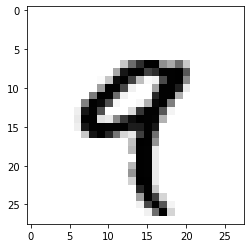

In [25]:
plt.imshow(digit, cmap=plt.cm.binary)
plt.show()

# Data Batches

En los modelos de Deep Learning, no se procesa el conjunto de datos completo de una vez; más bien, se dividen los datos en pequeños lotes (batches). En general, un conjunto de imágenes tendrá la forma `(samples, height, width, channels)`.

<div align="center">
    <img src="img/batch.png" alt="" width="25%" align="center" />
</div>

Entonces, por ejemplo, un lote de 128 imágenes en escala de grises de tamaño 256 × 256 podría almacenarse en un tensor de forma (128, 256, 256, 1), y un lote de 128 imágenes en color podría almacenarse en un tensor de forma (128, 256, 256, 3).

# Timeseries data or sequence data

Siempre que el tiempo importe en sus datos (o la noción de orden de secuencia), tiene sentido almacenarlo en un tensor 3D con un eje de tiempo explícito. Cada muestra se puede codificar como una secuencia de vectores (un tensor 2D) y, por lo tanto, un lote de datos se codificará como un tensor 3D de la forma `(samples, timesteps, features)`.

<div align="center">
    <img src="img/timeseries.png" alt="" width="40%" align="center" />
</div>

# Operaciones tensoriales

Los engranajes de las redes neuronales son las operaciones tensoriales.


<div align="center">
    <img src="img/engranajes.jpg" alt="" width="20%" align="center" />
</div>

### Operación elemento-a-elemento (element-wise): 

Es aquella operación que trabaja operando sobre cada uno de los valores del tensor por separado. Un ejemplo de este tipo de operaciones es la suma/resta vectorial.

In [26]:
vec_a = np.array([1,2,3,4])
vec_b = np.array([6,7,8,9])

print('Operación element-wise: {1} + {2} = {0}'.format(vec_a+vec_b,vec_a,vec_b))

Operación element-wise: [1 2 3 4] + [6 7 8 9] = [ 7  9 11 13]


### Operación matricial o tensor-wise: 
Es aquella operación que combina los elementos de el/los tensor/es para formar la salida. Ejemplos de este tipo de operaciones son el producto punto entre vectores y la multiplicación matricial.

In [27]:
vec_a = np.array([1,2,3,4])
vec_b = np.array([6,7,8,9])

print('Operación tensor-wise: {1} * {2} = {0}'.format(np.dot(vec_a,vec_b),vec_a,vec_b))

Operación tensor-wise: [1 2 3 4] * [6 7 8 9] = 80


### Tensor reshaping

Reorganizar sus filas y columnas para que coincidan con una forma destino. Naturalmente, el tensor remodelado tiene el mismo número total de coeficientes que el tensor inicial.

In [28]:
x = np.array([[0., 1.], [2., 3.], [4., 5.]])
x

array([[0., 1.],
       [2., 3.],
       [4., 5.]])

In [29]:
x.shape

(3, 2)

In [30]:
x = x.reshape((6, 1))
x

array([[0.],
       [1.],
       [2.],
       [3.],
       [4.],
       [5.]])

In [31]:
x.shape

(6, 1)

# Interpretación geométrica del aprendizaje profundo

Las redes neuronales consisten en básicamente puras operaciones tensoriales y todas estas operaciones son solo transformaciones geométricas de los datos de entrada. Por lo tanto, una red neuronal puede interpretarse como una transformación geométrica muy compleja en un espacio de alta dimensión, implementada a través de una larga serie de pasos simples.

<div align="center">
    <img src="img/geometric_representation.jpg" alt="" width="50%" align="center" />
</div>

# Optimización

Es el motor de las redes neuronales y consiste en encontrar el máximo o mínimo de una función.

<div align="center">
    <img src="img/Optimization.png" alt="" width="30%" align="center" />
</div>

## Derivada
Pendiente en cierto punto.
<div align="center">
    <img src="img/derivada.png" alt="" width="20%" align="center" />
</div>

## Gradiente

Es la derivada de una operación tensorial. Es la generalización del concepto de derivadas sobre funciones de entradas multidimensionales, es decir, a funciones que toman tensores como entradas.

## Descenso del gradiente

Dada una función diferenciable, es teóricamente posible encontrar su mínimo.

<div align="center">
    <img src="img/gradient descent 1d.png" alt="" width="30%" align="left" />
    <img src="img/gradient descent surface.png" alt="" width="30%" align="center" />
</div>

Existen múltiples variantes de SGD que toman en cuenta pasos anteriores para calcular el siguiente paso como Adagrad y RMSProp.

# Redes Neuronales



## Neurona de McCulloch-Pitts

El primer modelo computacional de una neurona artificial fue propuesto por Warren McCulloch (neurocientífico) y Walter Pitts (lógico) en 1943. Recibía solo entradas binarias, calculaba la sumatoria y el valor pasaba por una función escalón que entregaba una salida binaria.

<div align="center">
    <img src="img/McCulloch-Pitts.png" alt="" width="25%" align="center" />
</div>

# El Perceptrón
    
- En 1957, Frank Rosenblatt desarrolla el **perceptrón**, que es una red neuronal de una sola capa. 
- Este modelo era más general que la neurona de McCulloch-Pitts introduciendo el concepto de pesos numéricos (una medida de importancia) para las entradas y un mecanismo para aprender esos pesos. 
- Además, las entradas ya no están limitadas a valores booleanos. Sin embargo, al igual que la neurona de McCulloch-Pitts, solo se puede usar para implementar funciones linealmente separables.

<div align="center">
<img src="img/perceptron.png" alt="" width="30%" align="center" />
</div>

## ¿Cómo aprende el perceptrón?

En 1949, Donald Hebb sugirió que cuando una neurona biológica se comunica con otra neurona, la conexión entre estas dos neuronas se fortalece. Esta idea dio origen a: “Cells that fire together, wire together.”, lo que significa es que el peso de la conexión entre dos neuronas aumenta siempre que tengan la misma salida. 

<div align="center">
<img src="img/firewire.png" alt="" width="60%" align="center" />
</div>

### Perceptron learning rule (weight update)

El Perceptrón refuerza las conexiones que ayudan a reducir el error, es decir: por cada neurona de salida $j$ que produjo una predicción $\hat{y}_j$ incorrecta, la red refuerza los pesos de conexión de las entradas $i$ que habrían contribuido a la predicción correcta $y_j$:

$$ w_{i,j}^{(\mbox{next step})} = w_{i,j} + \eta (y_j - \hat{y}_j)x_i $$

La frontera de decisión de cada neurona de salida es lineal, por lo tanto, los perceptrones son incapaces de aprender patrones complejos. Sin embargo, si las instancias de entrenamiento son linealmente separables, Rosenblatt demostró que este algoritmo convergería a una solución. Esto se llama el teorema de convergencia del Perceptron.

# El Perceptrón Multicapa

<div align="center">
    <img src="img/MLP.png" alt="" width="50%" align="center" />
</div>

# Función de activación

Calcula el resultado (o "activación") de cada neurona, es decir, son la manera de transmitir la información generada por la combinación lineal de los pesos y las entradas.

Elegir una correcta función de activación, es crucial para el proceso de aprendizaje de la red.

In [32]:
def derivada(f, z, eps=0.000001):
    return (f(z + eps) - f(z - eps))/(2 * eps)

def Sigmoid(z):
    return 1 / (1 + np.exp(-z))

def ReLU(z):
    return np.maximum(0, z)

def leaky_relu(z, alpha=0.01):
    return np.maximum(alpha*z, z)

def Softmax(z):
    return np.exp(z)/np.sum(np.exp(z),axis=0)

In [33]:
def plot_activation_functions(axis=[-5, 5, -1.2, 1.2],
                              sigmoid=False,tanh=False,relu=False,leaky=False,softmax=False):
    z = np.linspace(-5,5,200)
    plt.figure(figsize=(11,4))
    plt.subplot(121)
    if sigmoid:
        plt.plot(z, Sigmoid(z), "b", ls="-", lw=2, label="Sigmoid")
    if tanh:
        plt.plot(z, np.tanh(z), "g", ls='-', lw=2, label="Tanh")
    if relu:
        plt.plot(z, ReLU(z), "orange", ls="-", lw=2, label="ReLU")
    if leaky:
        plt.plot(z, leaky_relu(z), "magenta", ls="-", lw=2, label="Leaky ReLU")
    if softmax:
        plt.plot(z, Softmax(z), "r", ls="-", lw=2, label="Softmax")
    plt.grid(True)
    plt.legend(loc="best", fontsize=14)
    plt.title("Funciones de Activación", fontsize=14)
    plt.axis(axis)
    plt.subplot(122)
    if sigmoid:
        plt.plot(z, derivada(Sigmoid, z), "b", ls="-", lw=2, label="Sigmoid")
    if tanh:
        plt.plot(z, derivada(np.tanh, z), "g", ls='-', lw=2, label="Tanh")
    if relu:
        plt.plot(z, derivada(ReLU, z), "orange", ls="-", lw=2, label="ReLU")
    if leaky:
        plt.plot(z, derivada(leaky_relu, z), "magenta", ls="-", lw=2, label="Leaky ReLU")
    if softmax:
        plt.plot(z, derivada(Softmax, z), "r", ls="-", lw=2, label="Softmax")
    plt.grid(True)
    plt.title("Derivadas", fontsize=14)
    plt.axis(axis)
    plt.show()

### Función Sigmoidal

La función sigmoidal (también conocida como logística), no-lineal y diferenciable, permite interpretar el output de las capas anteriores de una red como si fueran probabilidades (porque siempre entrega valores entre 0 y 1). El problema es que las gradientes tienden a cero, por lo tanto, las capas dejarán de aprender en cierto punto ("gradientes desvanecientes").

$$ Sigmoid(z) = \frac{1}{1+e^{-z}} $$

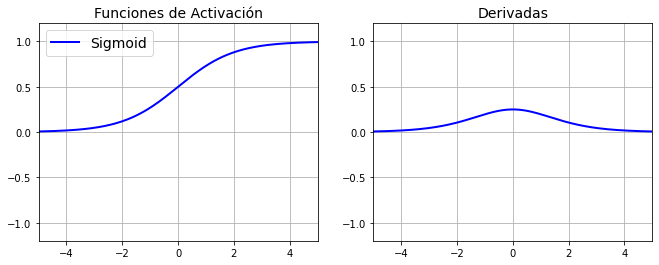

In [34]:
plot_activation_functions(sigmoid=True)

### Función tangente hiperbólica

La función $\tanh(z)$ es una versión reescalada de la sigmoidal, con un rango de salida entre $-1$ y $1$, pero también sufre del problema de las gradientes desvanecientes.

$$ Tanh(z) = \frac{e^z-e^{-z}}{e^z+e^{-z}} $$

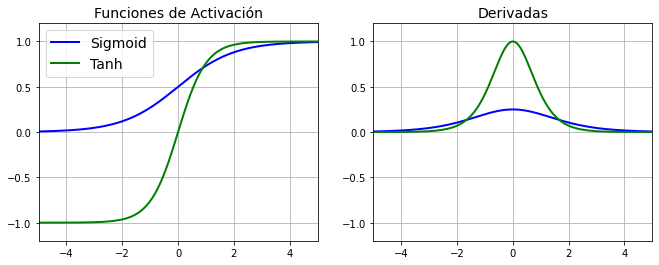

In [35]:
plot_activation_functions(sigmoid=True, tanh=True)

### Función ReLU (Rectified Linear Unit)

Se usa en capas ocultas, mejora el rendimiento de Tanh y Sigmoid porque involucra operaciones matemáticas más simples y corrige parcialmente el problema del gradiente desvaneciente (para $z>0$). Sin embargo, en la región $z<0$, el gradiente será cero y generará neuronas "moribundas".

$$ ReLU(z) = max(0,z) $$

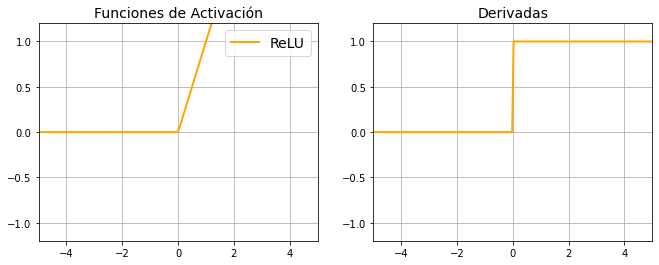

In [36]:
plot_activation_functions(relu=True)

### Función Leaky ReLU

LeakyRelu es una variante de ReLU. En lugar de ser cero cuando $z<0$, leaky ReLU permite una pequeña pendiente constante distinta de cero (generalmente, $\alpha=0.01$). Como desventaja, es incapaz de aprender relaciones complejas.

$$ \mbox{Leaky ReLU}(z) = max(\alpha z,z) $$

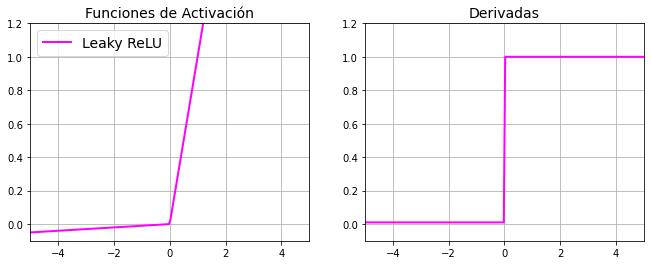

In [37]:
plot_activation_functions(axis=[-5, 5, -0.1, 1.2], leaky=True)

### Función Softmax

$$ \mbox{Softmax}(z) = \frac{e^{z}}{\sum e^{z}} $$

- También conocida como activación multinomial.
- Esta función es usada por lo general en la capa de salida de la red en clasificación.
- Resuelve el problema de más de dos clases que la Sigmoide no logra.
- Asegura que las probabilidades de cada clase sumen 1.

<div align="center">
    <img src="img/softmax.png" alt="" width="30%" align="center" />
</div>

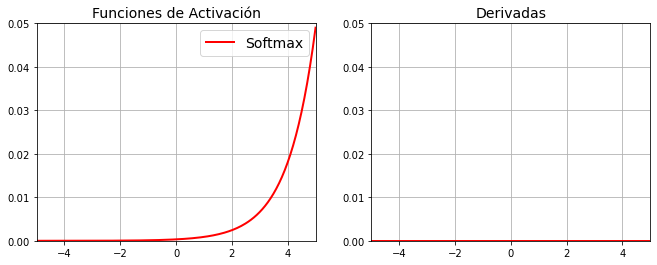

In [38]:
plot_activation_functions(axis=[-5,5, 0,0.05],softmax=True)

## ¿Cómo aprende el perceptrón multicapa?

- Durante muchos años, los investigadores lucharon por encontrar una manera de entrenar a los MLP, sin éxito. Pero en 1986, David Rumelhart, Geoffrey Hinton y Ronald Williams publicaron un artículo innovador que presentaba el algoritmo **backpropagation**, que todavía se usa en la actualidad. 

- En resumen, es simplemente Gradient Descent, utilizando una técnica eficiente para calcular los gradientes de forma automática en solo dos pasadas a través de la red (una hacia adelante y otra hacia atrás). El algoritmo es capaz de calcular el gradiente del error de la red con respecto a cada parámetro del modelo, es decir, puede averiguar cómo se debe ajustar cada peso de conexión para reducir el error. Una vez que tiene estos gradientes, simplemente realiza un paso de descenso de gradiente regular y todo el proceso se repite hasta que la red converge a la solución.

## Backpropagation

<div align="center">
    <img src="img/backpropagation.jpg" alt="" width="60%" align="center" />
</div>

# El proceso general

<div align="center">
    <img src="img/process.png" alt="" width="45%" align="center" />
</div>